In [1]:
from pathlib import Path
from IPython.display import display
import urllib.request
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Colab 원본의 Drive ID와 파일을 그대로 사용합니다.
# 다른 전처리 결과를 이 입력으로 대체하지 않습니다.
ORIGINAL_INPUTS = [{'id': '1ewxvBP9dj2hLI_dq6dKXSYwuMn7yXfUB', 'name': 'port_weather_2021_2024.csv', 'sha256': '9d2f0aeb3f7ed4f22469e366f006dda291af0a3988e8fceda59081fab586b477', 'bytes': 4630401, 'variable': 'weather', 'rows': 70127, 'columns': 16}, {'id': '1SzJijn97BQ0A8ChXHWEQXgZHV9LXoLuh', 'name': '체류시간_찐찐최종.csv', 'sha256': '8cd69287d211b4019f28bb5573663f2a925a10805ba9a4c201eb6702ed748f43', 'bytes': 3060919, 'variable': 'ship', 'rows': 33994, 'columns': 11}]

def 원본파일(정보):
    폴더 = Path.cwd() / "Drive_원본" / 정보["id"]
    폴더.mkdir(parents=True, exist_ok=True)
    파일 = 폴더 / 정보["name"]
    if not 파일.is_file():
        urllib.request.urlretrieve(
            "https://drive.google.com/uc?export=download&id=" + 정보["id"], 파일
        )
    if hashlib.sha256(파일.read_bytes()).hexdigest() != 정보["sha256"]:
        raise ValueError(f"검증한 Colab 원본과 다른 파일입니다: {파일}")
    return 파일

weather = pd.read_csv(원본파일(ORIGINAL_INPUTS[0]), low_memory=False)
ship = pd.read_csv(원본파일(ORIGINAL_INPUTS[1]), low_memory=False)
for 정보, 자료 in zip(ORIGINAL_INPUTS, [weather, ship]):
    if 자료.shape != (정보["rows"], 정보["columns"]):
        raise ValueError(f"원본 크기와 다릅니다: {정보['name']} {자료.shape}")
    print("원본 확인:", 정보["id"], 정보["name"], 자료.shape)
OUTPUT_DIR = Path.cwd() / "결과"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("기상 데이터:", weather.shape)
print("선박 데이터:", ship.shape)


원본 확인: 1ewxvBP9dj2hLI_dq6dKXSYwuMn7yXfUB port_weather_2021_2024.csv (70127, 16)
원본 확인: 1SzJijn97BQ0A8ChXHWEQXgZHV9LXoLuh 체류시간_찐찐최종.csv (33994, 11)
기상 데이터: (70127, 16)
선박 데이터: (33994, 11)


In [2]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text

# 각 그림의 실제 글자에도 글꼴을 적용해 재실행이나 테마 변경의 영향을 줄입니다.
_available_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((name for name in (
    "Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"
) if name in _available_fonts), None)
if KOREAN_FONT is None:
    raise RuntimeError("한글 글꼴을 찾지 못했습니다. 맑은 고딕 설치를 확인하세요.")

def 한글설정():
    plt.rcParams["font.family"] = KOREAN_FONT
    plt.rcParams["font.sans-serif"] = [KOREAN_FONT]
    plt.rcParams["axes.unicode_minus"] = False

def 그림표시():
    그림 = plt.gcf()
    한글설정()
    for 글자 in 그림.findobj(match=Text):
        글자.set_fontfamily(KOREAN_FONT)
    plt.show()
    plt.close(그림)

한글설정()
print("사용 글꼴:", KOREAN_FONT)


사용 글꼴: Malgun Gothic


In [3]:
print("기상 데이터:", weather.columns)
print("선박 데이터:", ship.columns)

기상 데이터: Index(['항만', '관측시각(KST)', '최대순간풍속(m/s)', '파고_유의파고(m)', '파고_최대파고(m)', '풍속(m/s)',
       '풍향(8방위)', '시정(10m)', '특보발효여부', '발효특보명', '풍랑특보명', '풍랑특보발효시각(KST)',
       '풍랑특보종료시각(KST)', '태풍특보명', '태풍특보발효시각(KST)', '태풍특보종료시각(KST)'],
      dtype='str')
선박 데이터: Index(['선박명', '총톤수', '항만구분', '터미널', '선사', '접안일시', '출항일시', '체류시간', '순수물동량',
       'Shift수량', '총작업량'],
      dtype='str')


In [4]:
print("기상 데이터:", weather.dtypes)
print("선박 데이터:", ship.dtypes)

기상 데이터: 항만                   str
관측시각(KST)            str
최대순간풍속(m/s)      float64
파고_유의파고(m)       float64
파고_최대파고(m)       float64
풍속(m/s)          float64
풍향(8방위)              str
시정(10m)          float64
특보발효여부             int64
발효특보명                str
풍랑특보명                str
풍랑특보발효시각(KST)        str
풍랑특보종료시각(KST)        str
태풍특보명                str
태풍특보발효시각(KST)        str
태풍특보종료시각(KST)        str
dtype: object
선박 데이터: 선박명            str
총톤수          int64
항만구분           str
터미널            str
선사             str
접안일시           str
출항일시           str
체류시간       float64
순수물동량          str
Shift수량        str
총작업량       float64
dtype: object


In [5]:
# 날짜 컬럼 변환
ship['접안일시'] = pd.to_datetime(ship['접안일시'])
ship['출항일시'] = pd.to_datetime(ship['출항일시'])

weather['관측시각(KST)'] = pd.to_datetime(weather['관측시각(KST)'])

# 데이터 확인
print(ship[['선박명', '터미널', '접안일시', '출항일시']].head())
print(weather[['항만', '관측시각(KST)', '특보발효여부']].head())

                      선박명   터미널                접안일시                출항일시
0        NORTHERN GENERAL  BNCT 2021-01-01 03:20:00 2021-01-01 19:00:00
1  PRESIDENT FD ROOSEVELT  BNCT 2021-01-01 15:20:00 2021-01-03 00:00:00
2     PRESIDENT CLEVELAND  BNCT 2021-01-02 10:20:00 2021-01-03 00:05:00
3         COSCO GUANGZHOU  BNCT 2021-01-01 21:25:00 2021-01-03 05:30:00
4            CONTSHIP DAY  BNCT 2021-01-03 09:15:00 2021-01-03 17:50:00
   항만           관측시각(KST)  특보발효여부
0  신항 2021-01-01 00:00:00       0
1  북항 2021-01-01 01:00:00       0
2  신항 2021-01-01 01:00:00       0
3  북항 2021-01-01 02:00:00       0
4  신항 2021-01-01 02:00:00       0


In [6]:
# 특보발효여부 숫자 변환
weather['특보발효여부'] = pd.to_numeric(
    weather['특보발효여부'], errors='coerce'
)

In [7]:
# 선박별 특보발효여부 연결
# 시간별 기상자료에서 특보 발효 시간만 추출
warning = weather[weather['특보발효여부'] == 1].copy()

# 선박별 특보 노출 여부
results = []

for _, s in ship.iterrows():

    matched = warning[
        (warning['항만'] == s['항만구분']) &
        (warning['관측시각(KST)'] < s['출항일시']) &
        (warning['관측시각(KST)'] + pd.Timedelta(hours=1) > s['접안일시'])
    ]

    results.append(int(len(matched) > 0))

ship['특보노출여부'] = results

print(ship['특보노출여부'].value_counts())

특보노출여부
0    29210
1     4784
Name: count, dtype: int64


In [8]:
print(
    ship.groupby(['터미널', '특보노출여부'])
        .size()
        .unstack(fill_value=0)
)

특보노출여부     0     1
터미널               
BNCT    3015   544
BPTC_G  5475   808
BPT_S   9786  1494
HPNT    2535   450
PNC     5738   988
PNIT    2661   500


In [9]:
# GT 기술통계
gt_stats = ship['총톤수'].describe(
    percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
)

gt_df = gt_stats.reset_index()
gt_df.columns = ['통계항목', 'GT']
gt_df['GT'] = gt_df['GT'].round(0).astype(int)

display(gt_df)

,통계항목,GT
0,count,33994
1,mean,41512
2,std,47627
3,min,1864
4,10%,7406
5,25%,9563
6,50%,17933
7,75%,68687
8,90%,113735
9,95%,143262


In [10]:
gt_check = pd.DataFrame({
    '항목': ['GT 결측치', 'GT 0 이하', 'GT 고유값 수'],
    '건수': [
        ship['총톤수'].isna().sum(),
        (ship['총톤수'] <= 0).sum(),
        ship['총톤수'].nunique()
    ]
})

display(gt_check)

,항목,건수
0,GT 결측치,0
1,GT 0 이하,0
2,GT 고유값 수,943


In [11]:
ship['총작업량'] = pd.to_numeric(
    ship['총작업량'].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
)

ship['체류시간'] = pd.to_numeric(ship['체류시간'], errors='coerce')

# 체류시간을 접안~출항 기준으로 다시 계산하여 대조
ship['계산체류시간'] = (
    ship['출항일시'] - ship['접안일시']
).dt.total_seconds() / 3600

# 데이터 품질 확인
check = pd.DataFrame({
    '항목': ['총톤수', '총작업량', '체류시간', '계산체류시간'],
    '결측치': [
        ship['총톤수'].isna().sum(),
        ship['총작업량'].isna().sum(),
        ship['체류시간'].isna().sum(),
        ship['계산체류시간'].isna().sum()
    ],
    '0 이하 건수': [
        (ship['총톤수'] <= 0).sum(),
        (ship['총작업량'] <= 0).sum(),
        (ship['체류시간'] <= 0).sum(),
        (ship['계산체류시간'] <= 0).sum()
    ]
})

display(check)

# 제공된 체류시간과 재계산 값이 다른 기록 확인
print('체류시간 불일치:',
      ((ship['체류시간'] - ship['계산체류시간']).abs() > 0.01).sum())


,항목,결측치,0 이하 건수
0,총톤수,0,0
1,총작업량,0,175
2,체류시간,0,0
3,계산체류시간,0,0


체류시간 불일치: 0


In [12]:
# 총작업량이 0인 선박 확인
zero_work = ship[ship['총작업량'] == 0]

# 터미널별 건수
zero_count = (
    zero_work.groupby('터미널')
    .size()
    .reset_index(name='작업량0_건수')
)

display(zero_count)

display(
    zero_work[
        ['선박명', '터미널', '총톤수', '체류시간', '총작업량']
    ].head(20).style.format({
        '총톤수': '{:,.0f}',
        '체류시간': '{:.2f}',
        '총작업량': '{:,.2f}'
    })
)

,터미널,작업량0_건수
0,BNCT,13
1,BPTC_G,108
2,BPT_S,23
3,HPNT,10
4,PNC,21


,선박명,터미널,총톤수,체류시간,총작업량
39,EVER SHINE,BNCT,"76,185",8.67,0.00
75,COSCO ITALY,BNCT,"154,592",2.17,0.00
80,GERDA MAERSK,BNCT,"99,002",2.00,0.00
132,CMA CGM ALHAMBRA,BNCT,"32,245",1.17,0.00
346,EVER FULL,BNCT,"116,295",1.58,0.00
449,COSCO NINGBO,BNCT,"109,149",3.67,0.00
458,CMA CGM CHENNAI,BNCT,"112,967",1.68,0.00
662,CAPE MOSS,BNCT,"35,878",2.23,0.00
761,XIN FEI ZHOU,BNCT,"90,757",2.83,0.00
764,OOCL UTAH,BNCT,"91,499",2.75,0.00


In [13]:
# 실제 하역작업이 있는 선박만 추출
ship_analysis = ship[ship['총작업량'] > 0].copy()

print("전체 기록:", len(ship))
print("분석 대상:", len(ship_analysis))
print("제외 기록:", len(ship) - len(ship_analysis))

전체 기록: 33994
분석 대상: 33819
제외 기록: 175


## 분석 대상이 33994척에서 33819로 줄어든 이유
- 총작업량이 0인 선박(175척)으로 사용시설허가의 입항목적이 양/적하와 관련되지않은 기타(수리, 급유 등)

In [14]:
# GT, 체류시간, 총작업량 상관관계 분석

corr = ship_analysis[
    ['총톤수', '체류시간', '총작업량']
].corr()

display(corr.round(3))

,총톤수,체류시간,총작업량
총톤수,1.000,0.557,0.807
체류시간,0.557,1.000,0.797
총작업량,0.807,0.797,1.000


체류시간은 GT 및 총작업량과 양의 상관관계를 보이며, 특히 총작업량과의 관계가 강하게 나타남.

따라서 기상특보 발효 조건에서 나타나는 체류시간 차이를 보다 타당하게 비교하기 위해서는 선박 규모와 화물 작업량의 차이를 고려한 분석이 필요

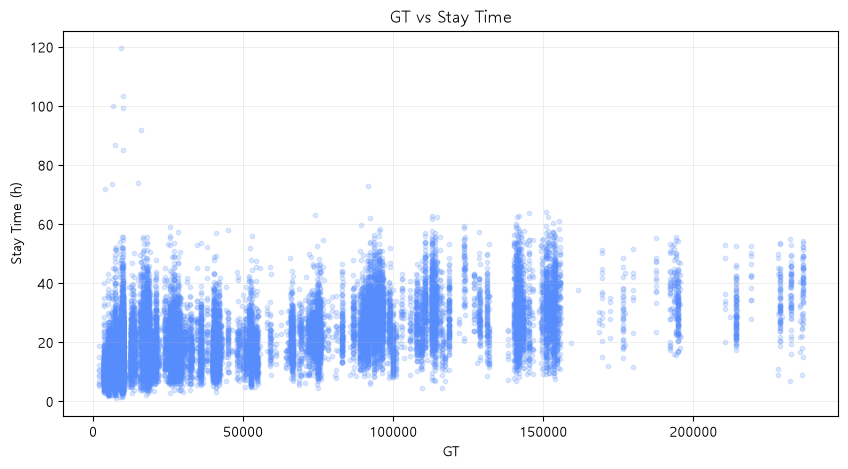

In [15]:
# GT와 체류시간 산점도
plt.figure(figsize=(10, 5))

plt.scatter(
    ship_analysis['총톤수'],
    ship_analysis['체류시간'],
    alpha=0.2,
    s=10
)

plt.xlabel('GT')
plt.ylabel('Stay Time (h)')
plt.title('GT vs Stay Time')
plt.grid(alpha=0.3)

그림표시()

GT가 클수록 체류시간이 길어지는 경향은 있지만, 같은 GT에서도 체류시간 차이가 상당히 크다

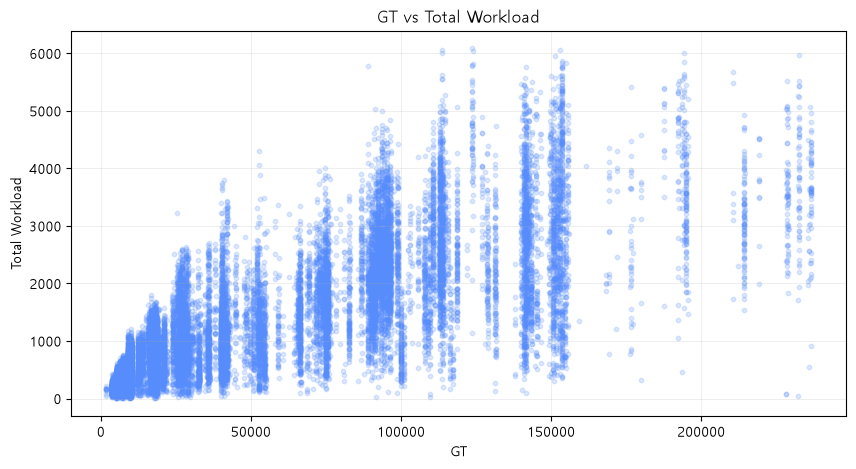

In [16]:
# GT와 총작업량 산점도

plt.figure(figsize=(10, 5))

plt.scatter(
    ship_analysis['총톤수'],
    ship_analysis['총작업량'],
    alpha=0.2,
    s=10
)

plt.xlabel('GT')
plt.ylabel('Total Workload')
plt.title('GT vs Total Workload')
plt.grid(alpha=0.3)

그림표시()

GT가 커질수록 총작업량이 증가하는 경향

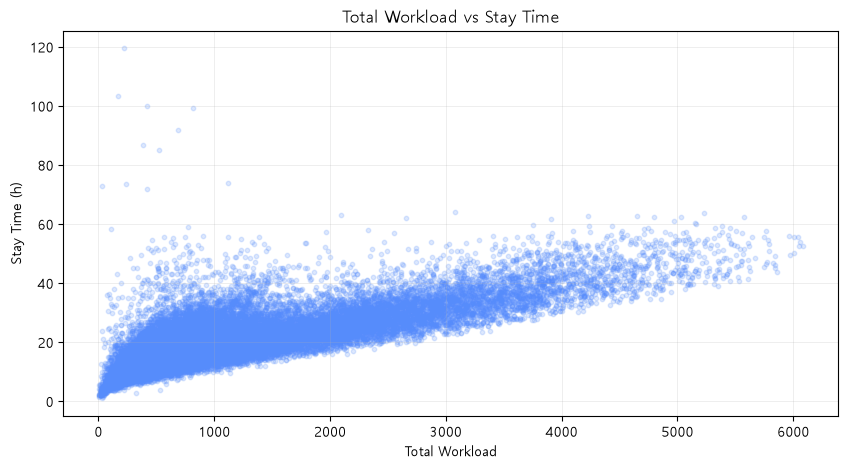

In [17]:
# 총작업량과 체류시간 산점도

plt.figure(figsize=(10, 5))

plt.scatter(
    ship_analysis['총작업량'],
    ship_analysis['체류시간'],
    alpha=0.2,
    s=10
)

plt.xlabel('Total Workload')
plt.ylabel('Stay Time (h)')
plt.title('Total Workload vs Stay Time')
plt.grid(alpha=0.3)

그림표시()


작업량이 같다고 체류시간이 반드시 같지는 않음

In [18]:
# 터미널별 주요 변수 분포 확인

terminal_stats = ship_analysis.groupby('터미널').agg(
    선박수=('선박명', 'count'),
    평균GT=('총톤수', 'mean'),
    중앙GT=('총톤수', 'median'),
    평균작업량=('총작업량', 'mean'),
    중앙작업량=('총작업량', 'median'),
    평균체류시간=('체류시간', 'mean'),
    중앙체류시간=('체류시간', 'median')
).reset_index()

display(
    terminal_stats.style.format({
        '선박수': '{:,.0f}',
        '평균GT': '{:,.0f}',
        '중앙GT': '{:,.0f}',
        '평균작업량': '{:,.0f}',
        '중앙작업량': '{:,.0f}',
        '평균체류시간': '{:.2f}',
        '중앙체류시간': '{:.2f}'
    })
)


,터미널,선박수,평균GT,중앙GT,평균작업량,중앙작업량,평균체류시간,중앙체류시간
0,BNCT,"3,546","84,850","91,410","1,526","1,338",23.84,22.58
1,BPTC_G,"6,175","12,856","9,923",566,515,15.99,15.00
2,BPT_S,"11,257","11,258","9,598",563,528,18.41,17.67
3,HPNT,"2,975","62,710","51,872","1,645","1,355",21.63,19.90
4,PNC,"6,705","69,285","65,792","1,632","1,358",20.76,19.25
5,PNIT,"3,161","78,161","89,174","2,015","1,803",25.48,23.50


In [19]:
# ⑦-2. 터미널별 특보 노출·비노출 선박 비교

warning_stats = ship_analysis.groupby(
    ['터미널', '특보노출여부']
).agg(
    선박수=('선박명', 'count'),
    평균GT=('총톤수', 'mean'),
    평균작업량=('총작업량', 'mean'),
    평균체류시간=('체류시간', 'mean'),
    중앙체류시간=('체류시간', 'median')
).reset_index()

display(
    warning_stats.style.format({
        '선박수': '{:,.0f}',
        '평균GT': '{:,.0f}',
        '평균작업량': '{:,.0f}',
        '평균체류시간': '{:.2f}',
        '중앙체류시간': '{:.2f}'
    })
)


,터미널,특보노출여부,선박수,평균GT,평균작업량,평균체류시간,중앙체류시간
0,BNCT,0,"3,003","84,362","1,500",23.43,22.08
1,BNCT,1,543,"87,543","1,666",26.08,24.97
2,BPTC_G,0,"5,384","12,802",563,15.69,15.00
3,BPTC_G,1,791,"13,227",587,18.08,16.92
4,BPT_S,0,"9,765","11,175",556,17.99,17.17
5,BPT_S,1,"1,492","11,801",607,21.11,20.00
6,HPNT,0,"2,526","61,738","1,615",21.17,19.50
7,HPNT,1,449,"68,182","1,817",24.26,23.00
8,PNC,0,"5,720","67,933","1,587",20.26,18.82
9,PNC,1,985,"77,137","1,897",23.62,22.25


모든 터미널에서 특보 노출 선박의 평균 체류시간이 비노출 선박보다 길게 나타났으나, 특보 노출 집단의 평균 GT와 총작업량 역시 높게 나타남.

In [20]:

# 터미널별 특보 노출 여부에 따른 평균·중앙값 비교

stay_stats = ship_analysis.groupby(
    ['터미널', '특보노출여부']
)['체류시간'].agg(['mean', 'median']).unstack()

stay_compare = pd.DataFrame({
    '비특보_평균': stay_stats[('mean', 0)],
    '특보_평균': stay_stats[('mean', 1)],
    '평균차이(h)': (
        stay_stats[('mean', 1)] - stay_stats[('mean', 0)]
    ),
    '비특보_중앙값': stay_stats[('median', 0)],
    '특보_중앙값': stay_stats[('median', 1)],
    '중앙값차이(h)': (
        stay_stats[('median', 1)] - stay_stats[('median', 0)]
    )
})

display(
    stay_compare.style.format('{:.2f}')
)


,비특보_평균,특보_평균,평균차이(h),비특보_중앙값,특보_중앙값,중앙값차이(h)
터미널,,,,,,
BNCT,23.43,26.08,2.65,22.08,24.97,2.88
BPTC_G,15.69,18.08,2.39,15.00,16.92,1.92
BPT_S,17.99,21.11,3.12,17.17,20.00,2.83
HPNT,21.17,24.26,3.09,19.50,23.00,3.50
PNC,20.26,23.62,3.35,18.82,22.25,3.43
PNIT,24.66,29.83,5.17,22.67,29.27,6.60


### 터미널별 평균·중앙값 체류시간 비교
- 모든 터미널에서 특보 노출 선박의 평균·중앙값 체류시간이 비노출 선박보다 높게 나타남. PNIT가 평균 +5.17h, 중앙값 +6.60h로 최대 차이를 보임.
- 중앙값에서도 증가 경향이 확인되었으나, GT·작업량 및 특보 노출 판정 편향을 고려한 추가 검증이 필요함.

In [21]:

# 특보 노출 여부별 GT·작업량 분포 비교

group_stats = ship_analysis.groupby(
    ['터미널', '특보노출여부']
).agg(
    선박수=('총톤수', 'size'),
    평균GT=('총톤수', 'mean'),
    중앙GT=('총톤수', 'median'),
    평균작업량=('총작업량', 'mean'),
    중앙작업량=('총작업량', 'median')
).reset_index()

display(
    group_stats.style.format({
        '선박수': '{:,.0f}',
        '평균GT': '{:,.0f}',
        '중앙GT': '{:,.0f}',
        '평균작업량': '{:,.0f}',
        '중앙작업량': '{:,.0f}'
    })
)


,터미널,특보노출여부,선박수,평균GT,중앙GT,평균작업량,중앙작업량
0,BNCT,0,"3,003","84,362","90,931","1,500","1,300"
1,BNCT,1,543,"87,543","91,498","1,666","1,555"
2,BPTC_G,0,"5,384","12,802","9,920",563,512
3,BPTC_G,1,791,"13,227","9,925",587,534
4,BPT_S,0,"9,765","11,175","9,587",556,522
5,BPT_S,1,"1,492","11,801","9,610",607,566
6,HPNT,0,"2,526","61,738","49,327","1,615","1,311"
7,HPNT,1,449,"68,182","52,581","1,817","1,633"
8,PNC,0,"5,720","67,933","54,675","1,587","1,309"
9,PNC,1,985,"77,137","74,656","1,897","1,764"


### 특보 노출 여부별 GT·작업량 분포 비교
- 모든 터미널에서 특보 노출 집단의 평균 GT와 총작업량이 높았으며, 특히 PNIT와 PNC에서 차이가 크게 나타남.
- 두 집단의 선박 특성이 동일하지 않으므로, 최종 KPI 산출 시 GT와 작업량 차이를 보정할 필요가 있음.

In [22]:

# 터미널별 GT 및 총작업량 분위수 확인

gt_dist = ship_analysis.groupby('터미널')['총톤수'].quantile(
    [0.25, 0.5, 0.75, 0.9]
).unstack()

gt_dist.columns = ['GT_25%', 'GT_50%', 'GT_75%', 'GT_90%']

work_dist = ship_analysis.groupby('터미널')['총작업량'].quantile(
    [0.25, 0.5, 0.75, 0.9]
).unstack()

work_dist.columns = ['작업량_25%', '작업량_50%', '작업량_75%', '작업량_90%']

display(gt_dist.style.format('{:,.0f}'))
display(work_dist.style.format('{:,.0f}'))


,GT_25%,GT_50%,GT_75%,GT_90%
터미널,,,,
BNCT,"40,447","91,410","117,340","150,783"
BPTC_G,"9,280","9,923","15,906","18,502"
BPT_S,"7,464","9,598","9,998","18,263"
HPNT,"25,375","51,872","106,154","141,328"
PNC,"26,050","65,792","94,489","149,944"
PNIT,"30,495","89,174","113,112","143,521"


,작업량_25%,작업량_50%,작업량_75%,작업량_90%
터미널,,,,
BNCT,762,"1,338","2,113","2,819"
BPTC_G,356,515,703,998
BPT_S,367,528,707,950
HPNT,773,"1,355","2,375","3,248"
PNC,645,"1,358","2,392","3,295"
PNIT,850,"1,803","2,974","3,988"


### 터미널별 GT·총작업량 분위수 분석
- 터미널별 선박 규모와 작업량 분포에 뚜렷한 차이가 있으며, BNCT·PNIT는 대형선 비중이 높고 BPTC_G·BPT_S는 소형선 중심으로 나타남.

In [23]:

# 터미널별 GT·작업량·체류시간 상관관계

results = []

for terminal, data in ship_analysis.groupby('터미널'):
    results.append({
        '터미널': terminal,
        'GT-체류시간': data['총톤수'].corr(data['체류시간']),
        'GT-작업량': data['총톤수'].corr(data['총작업량']),
        '작업량-체류시간': data['총작업량'].corr(data['체류시간'])
    })

terminal_corr = pd.DataFrame(results)

display(
    terminal_corr.style.format({
        'GT-체류시간': '{:.3f}',
        'GT-작업량': '{:.3f}',
        '작업량-체류시간': '{:.3f}'
    })
)


,터미널,GT-체류시간,GT-작업량,작업량-체류시간
0,BNCT,0.478,0.641,0.867
1,BPTC_G,0.271,0.526,0.698
2,BPT_S,0.322,0.512,0.759
3,HPNT,0.619,0.746,0.891
4,PNC,0.684,0.786,0.921
5,PNIT,0.641,0.719,0.904


###  터미널별 GT·작업량·체류시간 상관관계
- 모든 터미널에서 총작업량과 체류시간의 상관관계(r=0.698~0.921)가 GT와 체류시간의 상관관계보다 높게 나타남.

In [24]:

# 기상특보 유형별 발효 기록 확인

warning_type = weather[
    weather['특보발효여부'] == 1
]

warning_count = (
    warning_type['발효특보명']
    .value_counts()
    .reset_index()
)

warning_count.columns = ['특보유형', '관측행수']

display(warning_count)


,특보유형,관측행수
0,풍랑주의보,5988
1,태풍경보,122
2,풍랑경보,106
3,태풍주의보,48


,특보유형,관측행수
0,풍랑주의보,5988
1,태풍경보,122
2,풍랑경보,106
3,태풍주의보,48


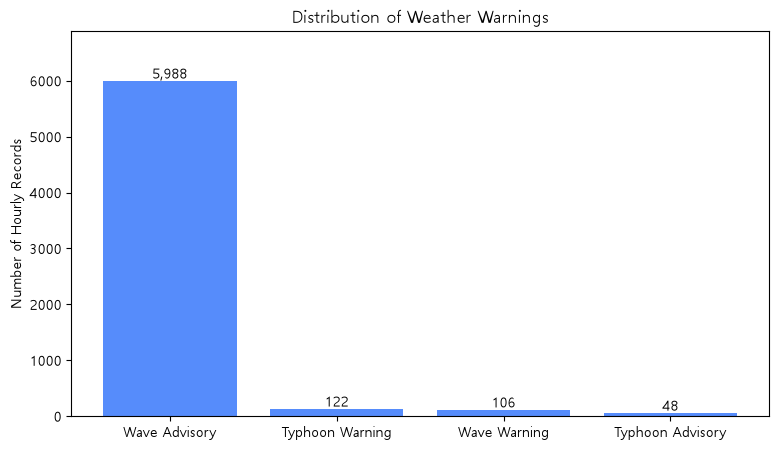

In [25]:
display(warning_count)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    range(len(warning_count)),
    warning_count['관측행수']
)

plt.xticks(
    range(len(warning_count)),
    warning_count['특보유형'].map({
        '풍랑주의보': 'Wave Advisory',
        '풍랑경보': 'Wave Warning',
        '태풍주의보': 'Typhoon Advisory',
        '태풍경보': 'Typhoon Warning',
    }).fillna(warning_count['특보유형']).tolist()
)

plt.ylabel('Number of Hourly Records')
plt.title('Distribution of Weather Warnings')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 50,
        f'{int(bar.get_height()):,}',
        ha='center'
    )

plt.ylim(0, warning_count['관측행수'].max() * 1.15)
그림표시()


,연도,특보관측시간수
0,2021,801
1,2022,670
2,2023,645
3,2024,1016


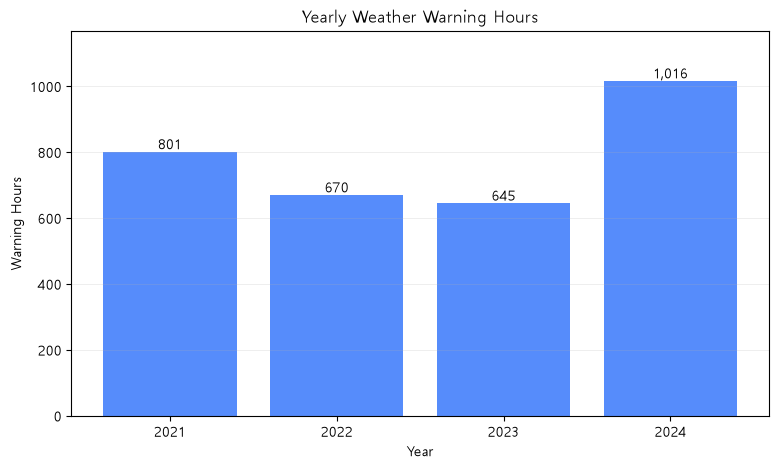

In [26]:

# 연도별 기상특보 발효시간 분포

# 특보 발효 자료만 추출
warning_year = weather[
    weather['특보발효여부'] == 1
].copy()

# 같은 시각에 기록된 북항·신항 중복 제거
warning_year = warning_year.drop_duplicates(
    subset=['관측시각(KST)']
)

# 연도 추출
warning_year['연도'] = warning_year['관측시각(KST)'].dt.year

# 연도별 특보 관측시간 집계
year_count = warning_year.groupby('연도').size().reset_index(
    name='특보관측시간수'
)


display(year_count)


plt.figure(figsize=(9, 5))

bars = plt.bar(
    year_count['연도'].astype(str),
    year_count['특보관측시간수']
)

plt.title('Yearly Weather Warning Hours')
plt.xlabel('Year')
plt.ylabel('Warning Hours')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{int(bar.get_height()):,}',
        ha='center',
        va='bottom'
    )

plt.ylim(0, year_count['특보관측시간수'].max() * 1.15)
plt.grid(axis='y', alpha=0.3)
그림표시()


### 연도별 기상특보 관측시간 분석
- 2021~2024년 특보 관측시간은 총 3,132시간이며, 2024년이 1,016시간(32.4%)으로 가장 높게 나타남.
- 연도별 특보 노출시간에 차이가 있으므로, 최종 KPI 분석 시 특정 연도에 결과가 집중되는지 검토할 필요가 있음.

,월,특보관측시간수
0,1,340
1,2,360
2,3,294
3,4,436
4,5,166
5,6,139
6,7,103
7,8,249
8,9,492
9,10,190


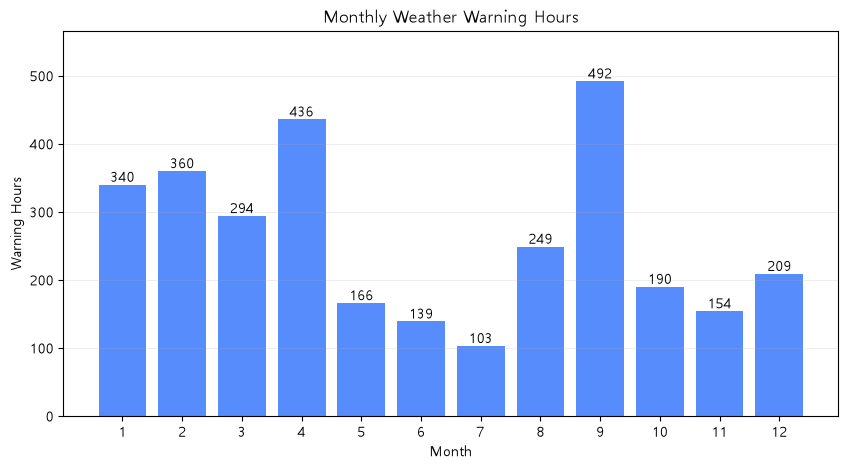

In [27]:

# 월별 기상특보 관측시간 분석

# 기존 중복 제거된 warning_year 사용
warning_year['월'] = warning_year['관측시각(KST)'].dt.month

month_count = (
    warning_year.groupby('월')
    .size()
    .reindex(range(1, 13), fill_value=0)
    .reset_index(name='특보관측시간수')
)

display(month_count)

# 월별 막대그래프
plt.figure(figsize=(10, 5))

bars = plt.bar(
    month_count['월'].astype(str),
    month_count['특보관측시간수']
)

plt.title('Monthly Weather Warning Hours')
plt.xlabel('Month')
plt.ylabel('Warning Hours')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f'{int(bar.get_height()):,}',
        ha='center',
        va='bottom'
    )

plt.ylim(0, month_count['특보관측시간수'].max() * 1.15)
plt.grid(axis='y', alpha=0.3)
그림표시()


### 월별 기상특보 관측시간 분석
- 2021~2024년 특보 관측시간은 9월(492시간), 4월(436시간)에 집중되었으며, 7월(103시간)이 가장 적게 나타남


발효특보명,태풍경보,태풍주의보,풍랑경보,풍랑주의보
월,,,,
1,0,0,8,332
2,0,0,21,339
3,0,0,6,288
4,0,0,0,436
5,0,0,0,166
6,0,0,0,139
7,0,0,0,103
8,24,11,0,214
9,37,13,18,424


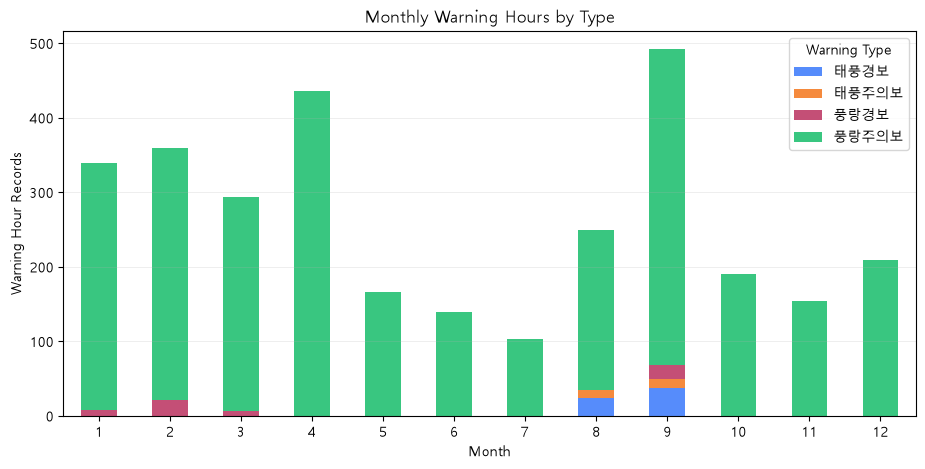

In [28]:

# 월별 특보 유형 분포

# 특보 발효 데이터
warning_month = weather[
    weather['특보발효여부'] == 1
].copy()

# 북항·신항의 동일 시각·동일 특보 중복 제거
warning_month = warning_month.drop_duplicates(
    subset=['관측시각(KST)', '발효특보명']
)

# 월 추출
warning_month['월'] = warning_month['관측시각(KST)'].dt.month

# 월별 특보 유형별 집계
month_type = warning_month.groupby(
    ['월', '발효특보명']
).size().unstack(fill_value=0)

month_type = month_type.reindex(range(1, 13), fill_value=0)

display(month_type)


ax = month_type.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 5)
)

plt.title('Monthly Warning Hours by Type')
plt.xlabel('Month')
plt.ylabel('Warning Hour Records')
plt.xticks(rotation=0)
plt.legend(title='Warning Type')
plt.grid(axis='y', alpha=0.3)
그림표시()


### 월별 기상특보 유형 분포
- 풍랑주의보가 대부분을 차지하며 4월(436시간), 9월(424시간)에 집중됨.
- 태풍특보는 8~9월에 나타나며, 특보 유형별 계절적 분포 차이가 확인됨.

In [29]:

# 항만별 특보·비특보 기상관측값 비교

weather_compare = weather.groupby(
    ['항만', '특보발효여부']
).agg(
    평균풍속=('풍속(m/s)', 'mean'),
    최대풍속=('풍속(m/s)', 'max'),
    평균유의파고=('파고_유의파고(m)', 'mean'),
    최대유의파고=('파고_유의파고(m)', 'max')
).reset_index()

display(
    weather_compare.style.format({
        '평균풍속': '{:.2f}',
        '최대풍속': '{:.2f}',
        '평균유의파고': '{:.2f}',
        '최대유의파고': '{:.2f}'
    })
)


,항만,특보발효여부,평균풍속,최대풍속,평균유의파고,최대유의파고
0,북항,0,1.96,10.50,0.56,2.60
1,북항,1,2.77,11.10,1.39,10.80
2,신항,0,2.17,10.44,0.38,2.30
3,신항,1,3.46,16.13,0.89,4.90


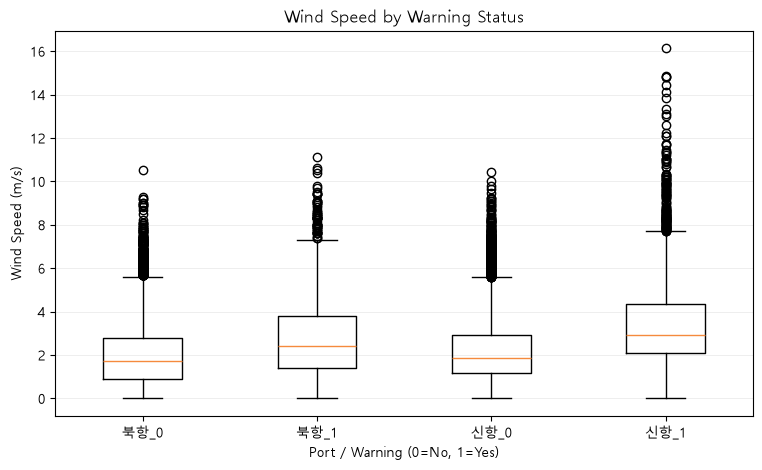

In [30]:

# 항만별 특보·비특보 풍속 분포

groups = []
labels = []

for port in ['북항', '신항']:
    for flag in [0, 1]:
        values = weather[
            (weather['항만'] == port) &
            (weather['특보발효여부'] == flag)
        ]['풍속(m/s)'].dropna()

        groups.append(values)
        labels.append(f'{port}_{flag}')

plt.figure(figsize=(9, 5))
plt.boxplot(groups, tick_labels=labels)

plt.title('Wind Speed by Warning Status')
plt.xlabel('Port / Warning (0=No, 1=Yes)')
plt.ylabel('Wind Speed (m/s)')
plt.grid(axis='y', alpha=0.3)
그림표시()


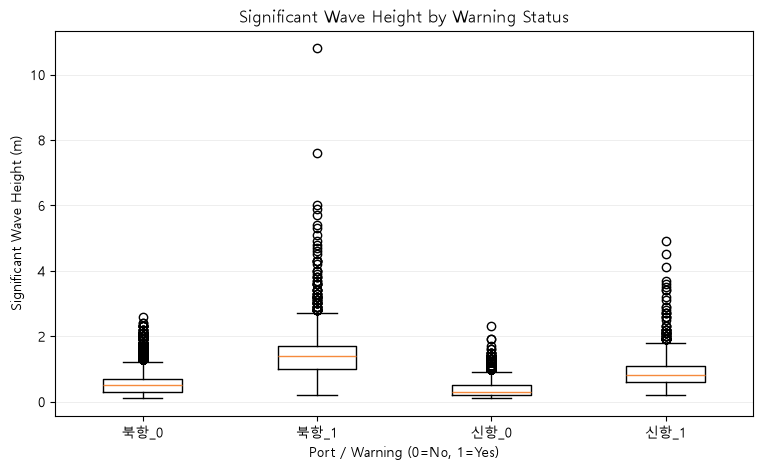

In [31]:
# 항만별 특보·비특보 유의파고 분포

groups = []
labels = []

for port in ['북항', '신항']:
    for flag in [0, 1]:
        values = weather[
            (weather['항만'] == port) &
            (weather['특보발효여부'] == flag)
        ]['파고_유의파고(m)'].dropna()

        groups.append(values)
        labels.append(f'{port}_{flag}')

plt.figure(figsize=(9, 5))
plt.boxplot(groups, tick_labels=labels)

plt.title('Significant Wave Height by Warning Status')
plt.xlabel('Port / Warning (0=No, 1=Yes)')
plt.ylabel('Significant Wave Height (m)')
plt.grid(axis='y', alpha=0.3)
그림표시()


### 기상특보 발효 여부에 따른 풍속·유의파고 분포
- 북항·신항 모두 특보 발효 시 풍속과 유의파고의 중앙값 및 분포 범위가 높아졌으며, 특히 유의파고에서 차이가 뚜렷하게 나타남.
- 북항 유의파고 최대 10.8m 등 극단값이 존재하므로 이상값 여부를 확인하고, 관측 지점과 특보 대상 해역의 차이를 고려할 필요가 있음.

In [32]:

# 특보 여부별 최대순간풍속 분석

gust_stats = weather.groupby(
    ['항만', '특보발효여부']
)['최대순간풍속(m/s)'].agg(
    관측수='count',
    평균='mean',
    중앙값='median',
    최대값='max',
    P90=lambda x: x.quantile(0.90),
    P95=lambda x: x.quantile(0.95)
).reset_index()

display(
    gust_stats.style.format({
        '관측수': '{:,.0f}',
        '평균': '{:.2f}',
        '중앙값': '{:.2f}',
        '최대값': '{:.2f}',
        'P90': '{:.2f}',
        'P95': '{:.2f}'
    })
)


,항만,특보발효여부,관측수,평균,중앙값,최대값,P90,P95
0,북항,0,"30,603",3.13,2.95,11.73,5.49,6.20
1,북항,1,"2,918",4.88,4.65,15.68,7.80,9.01
2,신항,0,"30,582",2.94,2.55,12.78,5.41,6.37
3,신항,1,"2,919",4.98,4.51,22.79,8.36,9.94


### 기상특보 발효 여부별 최대순간풍속 분석
- 특보 발효 시 최대순간풍속 중앙값은 북항 2.95→4.65m/s, 신항 2.55→4.51m/s로 증가함.
- 상위 5% 풍속(P95)도 북항 6.20→9.01m/s, 신항 6.37→9.94m/s로 증가하여 특보 기간의 돌풍 강도가 상대적으로 높게 나타남.

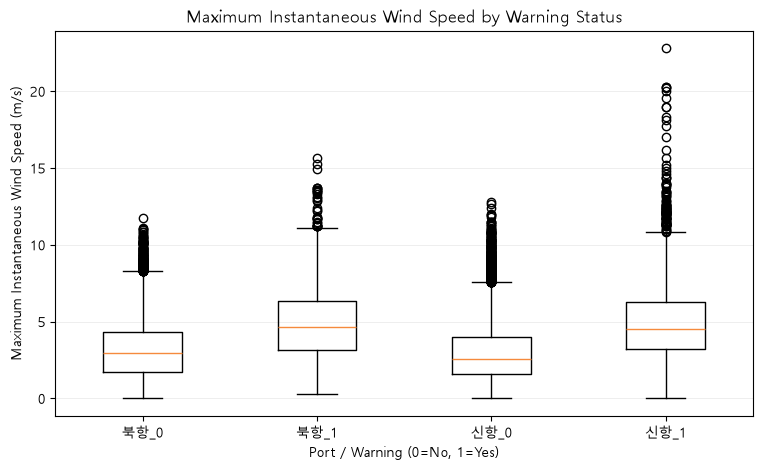

In [33]:

# 특보 여부별 최대순간풍속 박스플롯

import matplotlib.pyplot as plt

groups = []
labels = []

for port in ['북항', '신항']:
    for flag in [0, 1]:
        values = weather[
            (weather['항만'] == port) &
            (weather['특보발효여부'] == flag)
        ]['최대순간풍속(m/s)'].dropna()

        groups.append(values)
        labels.append(f'{port}_{flag}')

plt.figure(figsize=(9, 5))
plt.boxplot(groups, tick_labels=labels)

plt.title('Maximum Instantaneous Wind Speed by Warning Status')
plt.xlabel('Port / Warning (0=No, 1=Yes)')
plt.ylabel('Maximum Instantaneous Wind Speed (m/s)')
plt.grid(axis='y', alpha=0.3)

그림표시()


### 기상특보 여부별 최대순간풍속 분포
- 북항·신항 모두 특보 발효 시 최대순간풍속의 중앙값과 상위 분포가 높아졌으며, 특히 신항에서 강한 돌풍 관측 사례가 나타남.

In [34]:

# 항만 및 특보 여부별 기상변수 결측률(%)

cols = ['풍속(m/s)', '최대순간풍속(m/s)', '파고_유의파고(m)']

missing_results = []

for (port, flag), data in weather.groupby(['항만', '특보발효여부']):
    row = {'항만': port, '특보발효여부': flag, '전체행수': len(data)}

    for col in cols:
        row[col + '_결측률(%)'] = data[col].isna().mean() * 100

    missing_results.append(row)

missing_df = pd.DataFrame(missing_results)

display(
    missing_df.style.format({
        '전체행수': '{:,.0f}',
        '풍속(m/s)_결측률(%)': '{:.2f}',
        '최대순간풍속(m/s)_결측률(%)': '{:.2f}',
        '파고_유의파고(m)_결측률(%)': '{:.2f}'
    })
)


,항만,특보발효여부,전체행수,풍속(m/s)_결측률(%),최대순간풍속(m/s)_결측률(%),파고_유의파고(m)_결측률(%)
0,북항,0,"31,931",2.15,4.16,3.46
1,북항,1,"3,132",1.05,6.83,3.32
2,신항,0,"31,932",0.46,4.23,1.84
3,신항,1,"3,132",0.00,6.80,2.20


### 특보 여부별 기상변수 결측률 분석
- 풍속과 유의파고의 결측률은 대체로 낮으나, 최대순간풍속은 특보 기간에 북항 6.83%, 신항 6.80%로 증가함.
- 특보 발효 시 최대순간풍속의 결측이 상대적으로 많으므로, 관측값 비교와 해석에서 결측 편향 가능성을 고려해야 함.

In [35]:

# 최종 분석용 선박 데이터 확인

summary = ship_analysis.groupby(
    ['터미널', '특보노출여부']
).agg(
    선박수=('선박명', 'count'),
    평균체류시간=('체류시간', 'mean'),
    중앙체류시간=('체류시간', 'median')
).reset_index()

display(
    summary.style.format({
        '선박수': '{:,.0f}',
        '평균체류시간': '{:.2f}',
        '중앙체류시간': '{:.2f}'
    })
)


,터미널,특보노출여부,선박수,평균체류시간,중앙체류시간
0,BNCT,0,"3,003",23.43,22.08
1,BNCT,1,543,26.08,24.97
2,BPTC_G,0,"5,384",15.69,15.00
3,BPTC_G,1,791,18.08,16.92
4,BPT_S,0,"9,765",17.99,17.17
5,BPT_S,1,"1,492",21.11,20.00
6,HPNT,0,"2,526",21.17,19.50
7,HPNT,1,449,24.26,23.00
8,PNC,0,"5,720",20.26,18.82
9,PNC,1,985,23.62,22.25


### 터미널별 특보 노출 선박 최종 표본 확인
- 분석 대상 33,819건 중 특보 노출 4,760건, 비노출 29,059건으로 확인되었으며, 6개 터미널 모두 특보 노출 집단의 평균·중앙값 체류시간이 높게 나타남.
- 해당 결과는 GT·작업량을 보정하지 않은 기초 비교임.

In [36]:

# 기초 EDA 결과 데이터 저장

ship_analysis.to_csv(
    OUTPUT_DIR / 'PORTCAST_선박_특보노출_EDA.csv',
    index=False,
    encoding='utf-8-sig'
)

# 저장 확인
print("저장 완료:", len(ship_analysis), "건")


저장 완료: 33819 건


In [37]:
print("저장 파일:", OUTPUT_DIR / "PORTCAST_선박_특보노출_EDA.csv")


저장 파일: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Code\결과\PORTCAST_선박_특보노출_EDA.csv


In [38]:

# 선박별 노출 특보 유형 연결

warning_types = [
    '풍랑주의보', '풍랑경보',
    '태풍주의보', '태풍경보'
]

# 특보별 노출 여부를 기록할 컬럼
for name in warning_types:
    ship_analysis[name + '_노출'] = 0

# 항만 및 특보 유형별 시간대 연결
for port in ship_analysis['항만구분'].dropna().unique():

    for name in warning_types:

        times = weather[
            (weather['항만'] == port) &
            (weather['특보발효여부'] == 1) &
            (weather['발효특보명'] == name)
        ]['관측시각(KST)'].dropna().drop_duplicates()

        times = np.sort(times.to_numpy(dtype='datetime64[ns]'))

        if len(times) == 0:
            continue

        mask = ship_analysis['항만구분'] == port

        start = ship_analysis.loc[mask, '접안일시'].to_numpy(
            dtype='datetime64[ns]'
        )
        end = ship_analysis.loc[mask, '출항일시'].to_numpy(
            dtype='datetime64[ns]'
        )

        # 시간별 기록을 1시간 구간으로 간주
        left = np.searchsorted(
            times, start - np.timedelta64(1, 'h'), side='right'
        )
        right = np.searchsorted(times, end, side='left')

        ship_analysis.loc[mask, name + '_노출'] = (
            right > left
        ).astype(int)

# 노출된 특보명을 하나의 컬럼에 표시
cols = [name + '_노출' for name in warning_types]

ship_analysis['노출특보명'] = ship_analysis[cols].apply(
    lambda row: ', '.join(
        name for name in warning_types
        if row[name + '_노출'] == 1
    ) or '비노출',
    axis=1
)

# 특보 노출 여부 재계산
ship_analysis['특보노출여부'] = (
    ship_analysis[cols].max(axis=1)
)

# 결과 확인
display(
    ship_analysis[
        ['선박명', '터미널', '접안일시',
         '출항일시', '노출특보명', '특보노출여부']
    ].head(20)
)

display(ship_analysis['노출특보명'].value_counts().reset_index())


,선박명,터미널,접안일시,출항일시,노출특보명,특보노출여부
0,NORTHERN GENERAL,BNCT,2021-01-01 03:20:00,2021-01-01 19:00:00,비노출,0
1,PRESIDENT FD ROOSEVELT,BNCT,2021-01-01 15:20:00,2021-01-03 00:00:00,비노출,0
2,PRESIDENT CLEVELAND,BNCT,2021-01-02 10:20:00,2021-01-03 00:05:00,비노출,0
3,COSCO GUANGZHOU,BNCT,2021-01-01 21:25:00,2021-01-03 05:30:00,비노출,0
4,CONTSHIP DAY,BNCT,2021-01-03 09:15:00,2021-01-03 17:50:00,비노출,0
5,XIN TIAN JIN,BNCT,2021-01-03 01:55:00,2021-01-04 04:50:00,비노출,0
6,QI YUN HE,BNCT,2021-01-03 07:15:00,2021-01-04 06:45:00,비노출,0
7,CMA CGM RABELAIS,BNCT,2021-01-03 02:12:00,2021-01-04 09:00:00,비노출,0
8,APL GUAM,BNCT,2021-01-03 20:15:00,2021-01-04 13:00:00,비노출,0
9,OOCL UTAH,BNCT,2021-01-04 07:10:00,2021-01-04 20:50:00,비노출,0


,노출특보명,count
0,비노출,29059
1,풍랑주의보,4640
2,"풍랑주의보, 풍랑경보",105
3,"풍랑주의보, 태풍주의보, 태풍경보",13
4,"풍랑주의보, 풍랑경보, 태풍주의보, 태풍경보",1
5,"풍랑주의보, 풍랑경보, 태풍경보",1


In [39]:

# 특보 발효·종료시각 데이터 확인

cols = [
    '항만',
    '관측시각(KST)',
    '발효특보명',
    '풍랑특보발효시각(KST)',
    '풍랑특보종료시각(KST)',
    '태풍특보발효시각(KST)',
    '태풍특보종료시각(KST)'
]

display(
    weather[weather['특보발효여부'] == 1][cols]
    .drop_duplicates()
    .head(20)
)


,항만,관측시각(KST),발효특보명,풍랑특보발효시각(KST),풍랑특보종료시각(KST),태풍특보발효시각(KST),태풍특보종료시각(KST)
297,북항,2021-01-07 05:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
298,신항,2021-01-07 05:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
299,북항,2021-01-07 06:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
300,신항,2021-01-07 06:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
301,북항,2021-01-07 07:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
302,신항,2021-01-07 07:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
303,북항,2021-01-07 08:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
304,신항,2021-01-07 08:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
305,북항,2021-01-07 09:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN
306,신항,2021-01-07 09:00:00,풍랑주의보,2021-01-07 5:00,2021-01-07 20:00,NaN,NaN


In [40]:

# 특보 발효·종료 구간 정리

warning_events = weather[
    weather['특보발효여부'] == 1
].copy()

# 날짜형 변환
date_cols = [
    '풍랑특보발효시각(KST)',
    '풍랑특보종료시각(KST)',
    '태풍특보발효시각(KST)',
    '태풍특보종료시각(KST)'
]

for col in date_cols:
    warning_events[col] = pd.to_datetime(
        warning_events[col], errors='coerce'
    )

# 특보 유형별로 발효·종료시각 통합
wave = warning_events[
    warning_events['발효특보명'].str.contains('풍랑', na=False)
][[
    '항만', '발효특보명',
    '풍랑특보발효시각(KST)',
    '풍랑특보종료시각(KST)'
]].copy()

wave.columns = ['항만', '특보유형', '발효시각', '종료시각']

typhoon = warning_events[
    warning_events['발효특보명'].str.contains('태풍', na=False)
][[
    '항만', '발효특보명',
    '태풍특보발효시각(KST)',
    '태풍특보종료시각(KST)'
]].copy()

typhoon.columns = ['항만', '특보유형', '발효시각', '종료시각']

# 통합 및 중복 제거
warning_intervals = pd.concat(
    [wave, typhoon], ignore_index=True
).drop_duplicates()

# 유효한 시간 구간만 추출
warning_intervals = warning_intervals.dropna(
    subset=['발효시각', '종료시각']
)

warning_intervals = warning_intervals[
    warning_intervals['종료시각'] >
    warning_intervals['발효시각']
].copy()

# 특보 지속시간 계산
warning_intervals['지속시간(h)'] = (
    warning_intervals['종료시각'] -
    warning_intervals['발효시각']
).dt.total_seconds() / 3600

# 결과 확인
display(
    warning_intervals.groupby(['항만', '특보유형'])
    .size().reset_index(name='구간기록수')
)

display(
    warning_intervals.head(10).style.format({
        '지속시간(h)': '{:.2f}'
    })
)


,항만,특보유형,구간기록수
0,북항,태풍경보,5
1,북항,태풍주의보,4
2,북항,풍랑경보,6
3,북항,풍랑주의보,126
4,신항,태풍경보,5
5,신항,태풍주의보,4
6,신항,풍랑경보,6
7,신항,풍랑주의보,126


,항만,특보유형,발효시각,종료시각,지속시간(h)
0,북항,풍랑주의보,2021-01-07 05:00:00,2021-01-07 20:00:00,15.00
1,신항,풍랑주의보,2021-01-07 05:00:00,2021-01-07 20:00:00,15.00
30,북항,풍랑주의보,2021-01-18 12:00:00,2021-01-19 00:00:00,12.00
31,신항,풍랑주의보,2021-01-18 12:00:00,2021-01-19 00:00:00,12.00
54,북항,풍랑주의보,2021-01-23 11:00:00,2021-01-23 21:30:00,10.50
55,신항,풍랑주의보,2021-01-23 11:00:00,2021-01-23 21:30:00,10.50
76,북항,풍랑경보,2021-01-23 21:30:00,2021-01-24 06:00:00,8.50
77,신항,풍랑경보,2021-01-23 21:30:00,2021-01-24 06:00:00,8.50
92,북항,풍랑주의보,2021-01-24 06:00:00,2021-01-25 05:00:00,23.00
93,신항,풍랑주의보,2021-01-24 06:00:00,2021-01-25 05:00:00,23.00


In [41]:

# 특보 발효 구간 중첩 확인

check = warning_intervals.sort_values(
    ['항만', '발효시각', '종료시각']
).copy()

# 같은 항만에서 이전 특보들의 가장 늦은 종료시각
check['이전종료시각'] = check.groupby('항만')['종료시각'].transform(
    lambda x: x.cummax().shift(1)
)

# 이전 특보가 종료되기 전에 다음 특보가 시작됐는지 확인
check['중첩여부'] = (
    check['발효시각'] < check['이전종료시각']
)

display(
    check.groupby('항만')['중첩여부']
    .agg(['sum', 'count'])
    .rename(columns={'sum': '중첩구간수', 'count': '전체구간수'})
)

# 실제 중첩된 구간 확인
display(
    check[check['중첩여부']][
        ['항만', '특보유형', '발효시각',
         '종료시각', '이전종료시각']
    ].head(20)
)


,중첩구간수,전체구간수
항만,,
북항,0,141
신항,0,141


,항만,특보유형,발효시각,종료시각,이전종료시각


### 기상특보 발효 구간 중첩 검증
- 북항·신항 각각 141개 특보 구간을 확인했으며, 두 항만 모두 시간 중첩은 0건으로 나타남.
- 따라서 정리된 특보 구간을 기준으로 선박별 특보 유형별 노출시간 및 전체 노출시간을 중복 없이 계산할 수 있음.

In [42]:

# 선박별 특보 노출시간 계산

warning_types = ['풍랑주의보', '풍랑경보', '태풍주의보', '태풍경보']

# 날짜 형식 확인
ship_analysis['접안일시'] = pd.to_datetime(ship_analysis['접안일시'])
ship_analysis['출항일시'] = pd.to_datetime(ship_analysis['출항일시'])

# 특보 유형별 노출시간 컬럼 생성
for name in warning_types:
    ship_analysis[name + '_노출시간(h)'] = 0.0

# 항만별, 특보 구간별로 겹치는 시간 계산
for _, event in warning_intervals.iterrows():

    mask = ship_analysis['항만구분'] == event['항만']

    overlap_start = ship_analysis.loc[mask, '접안일시'].clip(
        lower=event['발효시각']
    )
    overlap_end = ship_analysis.loc[mask, '출항일시'].clip(
        upper=event['종료시각']
    )

    hours = (
        (overlap_end - overlap_start)
        .dt.total_seconds()
        .div(3600)
        .clip(lower=0)
        .fillna(0)
    )

    col = event['특보유형'] + '_노출시간(h)'

    ship_analysis.loc[mask, col] += hours

# 전체 특보 노출시간
hour_cols = [name + '_노출시간(h)' for name in warning_types]

ship_analysis['전체특보노출시간(h)'] = ship_analysis[hour_cols].sum(axis=1)

# 노출 여부와 특보명
ship_analysis['특보노출여부'] = (
    ship_analysis['전체특보노출시간(h)'] > 0
).astype(int)

ship_analysis['노출특보명'] = ship_analysis.apply(
    lambda row: ', '.join(
        name for name in warning_types
        if row[name + '_노출시간(h)'] > 0
    ) or '비노출',
    axis=1
)

# 체류시간 대비 특보 노출비율
ship_analysis['특보노출비율(%)'] = (
    ship_analysis['전체특보노출시간(h)']
    / ship_analysis['체류시간'].where(ship_analysis['체류시간'] > 0)
    * 100
)


display(
    ship_analysis[
        ['선박명', '터미널', '체류시간', '노출특보명',
         '전체특보노출시간(h)', '특보노출비율(%)']
    ].head(20).style.format({
        '체류시간': '{:.2f}',
        '전체특보노출시간(h)': '{:.2f}',
        '특보노출비율(%)': '{:.2f}'
    })
)


,선박명,터미널,체류시간,노출특보명,전체특보노출시간(h),특보노출비율(%)
0,NORTHERN GENERAL,BNCT,15.67,비노출,0.00,0.00
1,PRESIDENT FD ROOSEVELT,BNCT,32.67,비노출,0.00,0.00
2,PRESIDENT CLEVELAND,BNCT,13.75,비노출,0.00,0.00
3,COSCO GUANGZHOU,BNCT,32.08,비노출,0.00,0.00
4,CONTSHIP DAY,BNCT,8.58,비노출,0.00,0.00
5,XIN TIAN JIN,BNCT,26.92,비노출,0.00,0.00
6,QI YUN HE,BNCT,23.50,비노출,0.00,0.00
7,CMA CGM RABELAIS,BNCT,30.80,비노출,0.00,0.00
8,APL GUAM,BNCT,16.75,비노출,0.00,0.00
9,OOCL UTAH,BNCT,13.67,비노출,0.00,0.00


### 선박별 기상특보 노출시간 산출
- 선박의 접안-출항 구간과 특보 발효-종료 구간을 연결한 결과, 특보 노출 선박은 4,763건으로 산출됨.
- 노출시간이 체류시간을 초과한 사례는 0건

In [43]:
# 기존 특보 노출 판정과 새 계산 결과 비교

comparison = ship_analysis.copy()

# 원본 ship의 기존 판정값을 행 인덱스로 연결
comparison['기존특보노출여부'] = ship.loc[
    comparison.index, '특보노출여부'
]

different = comparison[
    comparison['기존특보노출여부'] !=
    comparison['특보노출여부']
]

display(
    different[
        ['선박명', '터미널', '접안일시', '출항일시',
         '기존특보노출여부', '특보노출여부',
         '노출특보명', '전체특보노출시간(h)']
    ]
)


,선박명,터미널,접안일시,출항일시,기존특보노출여부,특보노출여부,노출특보명,전체특보노출시간(h)
10077,RELIANCE,BPT_S,2021-01-31 10:10:00,2021-02-01 07:00:00,0,1,풍랑주의보,0.5
10223,CONMAR MOON,BPT_S,2021-02-20 23:20:00,2021-02-21 15:00:00,0,1,풍랑주의보,0.5
30934,MSC CARLOTTA,PNIT,2021-02-20 20:30:00,2021-02-21 15:00:00,0,1,풍랑주의보,0.5


In [44]:
# 추가된 3건의 특보 노출 시점 확인

results = []

for _, vessel in different.iterrows():
    matched = warning_intervals[
        (warning_intervals['항만'] == vessel['항만구분']) &
        (warning_intervals['발효시각'] < vessel['출항일시']) &
        (warning_intervals['종료시각'] > vessel['접안일시'])
    ]

    for _, event in matched.iterrows():
        if event['발효시각'] <= vessel['접안일시']:
            timing = '접안 시 노출'
        elif event['종료시각'] >= vessel['출항일시']:
            timing = '출항 시 노출'
        else:
            timing = '체류 중 노출'

        results.append({
            '선박명': vessel['선박명'],
            '접안일시': vessel['접안일시'],
            '출항일시': vessel['출항일시'],
            '특보유형': event['특보유형'],
            '특보발효': event['발효시각'],
            '특보종료': event['종료시각'],
            '노출시점': timing
        })

display(pd.DataFrame(results))

,선박명,접안일시,출항일시,특보유형,특보발효,특보종료,노출시점
0,RELIANCE,2021-01-31 10:10:00,2021-02-01 07:00:00,풍랑주의보,2021-02-01 06:30:00,2021-02-01 14:00:00,출항 시 노출
1,CONMAR MOON,2021-02-20 23:20:00,2021-02-21 15:00:00,풍랑주의보,2021-02-21 14:30:00,2021-02-22 04:00:00,출항 시 노출
2,MSC CARLOTTA,2021-02-20 20:30:00,2021-02-21 15:00:00,풍랑주의보,2021-02-21 14:30:00,2021-02-22 04:00:00,출항 시 노출


### 신규 특보 노출 3건의 발생 시점 검증
- 추가된 3건은 모두 풍랑주의보 발효 이후 30분 이내 출항한 선박으로, 접안 중 특보에 실제 노출된 사례임.

In [45]:

# 선박별 기상관측값 통합

final_df = ship_analysis.copy()

final_df['접안일시'] = pd.to_datetime(final_df['접안일시'])
final_df['출항일시'] = pd.to_datetime(final_df['출항일시'])
weather['관측시각(KST)'] = pd.to_datetime(weather['관측시각(KST)'])

weather_cols = {
    '풍속(m/s)': ('평균풍속', '최대풍속'),
    '최대순간풍속(m/s)': ('평균순간풍속', '최대순간풍속'),
    '파고_유의파고(m)': ('평균유의파고', '최대유의파고'),
    '파고_최대파고(m)': ('평균최대파고', '최대관측파고'),
    '시정(10m)': ('평균시정', '최소시정')
}

for col in weather_cols:
    weather[col] = pd.to_numeric(weather[col], errors='coerce')

new_cols = ['기상관측건수']
for names in weather_cols.values():
    new_cols.extend(names)

for col in new_cols:
    final_df[col] = np.nan

# 항만별 기상자료 연결
for port in final_df['항만구분'].dropna().unique():

    w = weather[weather['항만'] == port].copy()
    w = w.sort_values('관측시각(KST)')
    w = w.drop_duplicates('관측시각(KST)')

    times = w['관측시각(KST)'].to_numpy(dtype='datetime64[ns]')

    for idx, vessel in final_df[
        final_df['항만구분'] == port
    ].iterrows():

        start = vessel['접안일시']
        end = vessel['출항일시']

        if pd.isna(start) or pd.isna(end) or end <= start:
            continue

        left = np.searchsorted(times, np.datetime64(start))
        right = np.searchsorted(times, np.datetime64(end))

        selected = w.iloc[left:right]
        final_df.at[idx, '기상관측건수'] = len(selected)

        for col, names in weather_cols.items():
            values = selected[col].dropna()

            if len(values) == 0:
                continue

            final_df.at[idx, names[0]] = values.mean()

            if col == '시정(10m)':
                final_df.at[idx, names[1]] = values.min()
            else:
                final_df.at[idx, names[1]] = values.max()

# 결과 확인
display(
    final_df[
        ['선박명', '터미널', '체류시간', '노출특보명',
         '전체특보노출시간(h)', '평균풍속',
         '최대순간풍속', '평균유의파고',
         '최대유의파고', '최소시정']
    ].head(20).style.format({
        '체류시간': '{:.2f}',
        '전체특보노출시간(h)': '{:.2f}',
        '평균풍속': '{:.2f}',
        '최대순간풍속': '{:.2f}',
        '평균유의파고': '{:.2f}',
        '최대유의파고': '{:.2f}',
        '최소시정': '{:.2f}'
    })
)

print('전체 선박 건수:', len(final_df))
print('특보 노출 건수:', final_df['특보노출여부'].sum())
print('기상관측 0건:', (final_df['기상관측건수'] == 0).sum())


,선박명,터미널,체류시간,노출특보명,전체특보노출시간(h),평균풍속,최대순간풍속,평균유의파고,최대유의파고,최소시정
0,NORTHERN GENERAL,BNCT,15.67,비노출,0.00,2.35,nan,0.31,0.40,5000.00
1,PRESIDENT FD ROOSEVELT,BNCT,32.67,비노출,0.00,2.13,nan,0.26,0.40,4842.00
2,PRESIDENT CLEVELAND,BNCT,13.75,비노출,0.00,2.76,nan,0.25,0.30,4842.00
3,COSCO GUANGZHOU,BNCT,32.08,비노출,0.00,2.17,nan,0.25,0.30,4842.00
4,CONTSHIP DAY,BNCT,8.58,비노출,0.00,2.70,nan,0.26,0.30,5000.00
5,XIN TIAN JIN,BNCT,26.92,비노출,0.00,2.54,nan,0.26,0.30,4905.00
6,QI YUN HE,BNCT,23.50,비노출,0.00,2.29,nan,0.26,0.30,4219.00
7,CMA CGM RABELAIS,BNCT,30.80,비노출,0.00,2.46,nan,0.26,0.30,4182.00
8,APL GUAM,BNCT,16.75,비노출,0.00,1.86,nan,0.24,0.30,4119.00
9,OOCL UTAH,BNCT,13.67,비노출,0.00,1.62,nan,0.20,0.20,3679.00


전체 선박 건수: 33819
특보 노출 건수: 4763
기상관측 0건: 0


In [46]:

# 통합 기상변수 결측 확인

check_cols = [
    '평균풍속', '최대풍속',
    '평균순간풍속', '최대순간풍속',
    '평균유의파고', '최대유의파고',
    '평균최대파고', '최대관측파고',
    '평균시정', '최소시정'
]

missing = pd.DataFrame({
    '결측건수': final_df[check_cols].isna().sum(),
    '결측률(%)': final_df[check_cols].isna().mean() * 100
})

display(
    missing.style.format({
        '결측건수': '{:,.0f}',
        '결측률(%)': '{:.2f}'
    })
)


,결측건수,결측률(%)
평균풍속,140,0.41
최대풍속,140,0.41
평균순간풍속,"1,363",4.03
최대순간풍속,"1,363",4.03
평균유의파고,545,1.61
최대유의파고,545,1.61
평균최대파고,545,1.61
최대관측파고,545,1.61
평균시정,24,0.07
최소시정,24,0.07


In [47]:

# 최종 통합 데이터 저장 및 다운로드

filename = OUTPUT_DIR / 'PORTCAST_선박_기상_특보노출시간_최종.csv'

final_df.to_csv(
    filename,
    index=False,
    encoding='utf-8-sig',
    float_format='%.2f'
)

print("저장 파일:", filename)

print('최종 저장 건수:', len(final_df))
print('특보 노출 건수:', final_df['특보노출여부'].sum())
print('전체 컬럼 수:', len(final_df.columns))


저장 파일: C:\work\Port_Cast_Final\2.Data_Integrated Preprocessing\Code\결과\PORTCAST_선박_기상_특보노출시간_최종.csv
최종 저장 건수: 33819
특보 노출 건수: 4763
전체 컬럼 수: 35


In [48]:
# 입력과 원본 분석 조건에 따른 행 수를 명시적으로 확인합니다.
if len(ship) != ORIGINAL_INPUTS[1]["rows"]:
    raise ValueError("원본 선박 행 수가 바뀌었습니다.")
if not final_df.index.equals(ship_analysis.index):
    raise ValueError("기상 연결 중 분석 대상의 행 또는 순서가 바뀌었습니다.")
입력검증 = pd.DataFrame({
    "단계": ["원본 선박", "원본 조건: 총작업량 > 0", "최종 저장"],
    "행수": [len(ship), len(ship_analysis), len(final_df)],
})
입력검증.to_csv(OUTPUT_DIR / "입력과결과_행수검증.csv", index=False, encoding="utf-8-sig")
display(입력검증)


,단계,행수
0,원본 선박,33994
1,원본 조건: 총작업량 > 0,33819
2,최종 저장,33819
